In [1]:
import os
import sys
import re
import torch

ROOT = "/home/jovyan/work/isllm"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
os.chdir(ROOT)

from isllm.generation import generate, load_model_from_dir  
from isllm.tokenizer import load_tokenizer  
from transformers import AutoModelForCausalLM, MistralConfig

device = "cuda" if torch.cuda.is_available() else "cpu"

# Загрузка токенизатора
tokenizer_dir = os.path.join(ROOT, "tokenizer/final")
tokenizer = load_tokenizer(tokenizer_dir)

# Загрузка последнего чекпоинта
base_dir = os.path.join(ROOT, "checkpoints/large")
latest_ckpt = None

if os.path.exists(base_dir):
    subdirs = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    checkpoints = []
    for d in subdirs:
        match = re.match(r"checkpoint-(\d+)", d)
        if match:
            checkpoints.append((int(match.group(1)), d))
            
    if checkpoints:
        checkpoints.sort(key=lambda x: x[0], reverse=True)
        latest_ckpt = os.path.join(base_dir, checkpoints[0][1])
    elif "checkpoint_interrupted" in subdirs:
        latest_ckpt = os.path.join(base_dir, "checkpoint_interrupted")
    elif os.path.exists(os.path.join(base_dir, "model.safetensors")) or os.path.exists(os.path.join(base_dir, "pytorch_model.bin")):
        latest_ckpt = base_dir

if not latest_ckpt:
    raise FileNotFoundError(f"В папке {base_dir} не найдено ни одного чекпоинта!")

print(f"Найден последний чекпоинт: {latest_ckpt}")

# 3. Загрузка модели
try:
    model = load_model_from_dir(latest_ckpt, device=device)
except Exception as e:
    print(f"Загрузка не удалась. Причина: {e}")
    
    config = MistralConfig(
        vocab_size=16384,
        hidden_size=640,
        num_hidden_layers=16,
        num_attention_heads=10,
        max_position_embeddings=1024,
        tie_word_embeddings=True,
    )
    model = AutoModelForCausalLM.from_pretrained(
        latest_ckpt,
        config=config,
        local_files_only=True,
    )
    model = model.to(device)
    model.eval()

print("device:", device)
print("model:", type(model).__name__)
print("params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))

Найден последний чекпоинт: /home/jovyan/work/isllm/checkpoints/large/checkpoint-129000


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

device: cuda
model: MistralForCausalLM
params (M): 89.13


## Генерация при разных температурах

In [2]:

# 0.3

from isllm.training import generate_simple, load_prompts
from isllm.tokenizer import load_tokenizer
import torch


prompts = [
    "Höfuðborg Íslands er ",
    "Ísland er ",
    "Íslenska er ",
]

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)


for prompt in prompts:
    output_text = generate_simple( 
        model=model, 
        tokenizer=tokenizer, 
        prompt=prompt, 
        max_new_tokens=50, 
        device=device
    )
    print(f"Промпт: {prompt}")
    print(f"Ответ: {output_text}")
    print("-" * 60)

Промпт: Höfuðborg Íslands er 
Ответ: Höfuðborg Íslands er yst á Kjalarnesi, þar sem hún hefur verið síðustu ár. Þar búa um 100 manns og eru þeir í raun að mestu leyti erlendir ferðamenn.„Það var mjög gaman að sjá hvernig þetta fór af stað,“ segir Magnús Hlynur Hreiðarsson hjá S
------------------------------------------------------------
Промпт: Ísland er 
Ответ: Ísland er yndislegt fólk og það hefur verið að gera allt til þess að koma því í gott stand. Það var ekki bara gaman þegar við vorum saman heldur líka mjög skemmtilegt.“
------------------------------------------------------------
Промпт: Íslenska er 
Ответ: Íslenska er yndislegt fólk og það hefur verið svo lengi. Það var ekki fyrr en ég kom heim að ég fór í vinnuna til þess að læra eitthvað nýtt, þá fékk ég loksins tækifæri á því.“„Ég hef alltaf haft mikinn áhuga á íþróttum,“ segir
------------------------------------------------------------


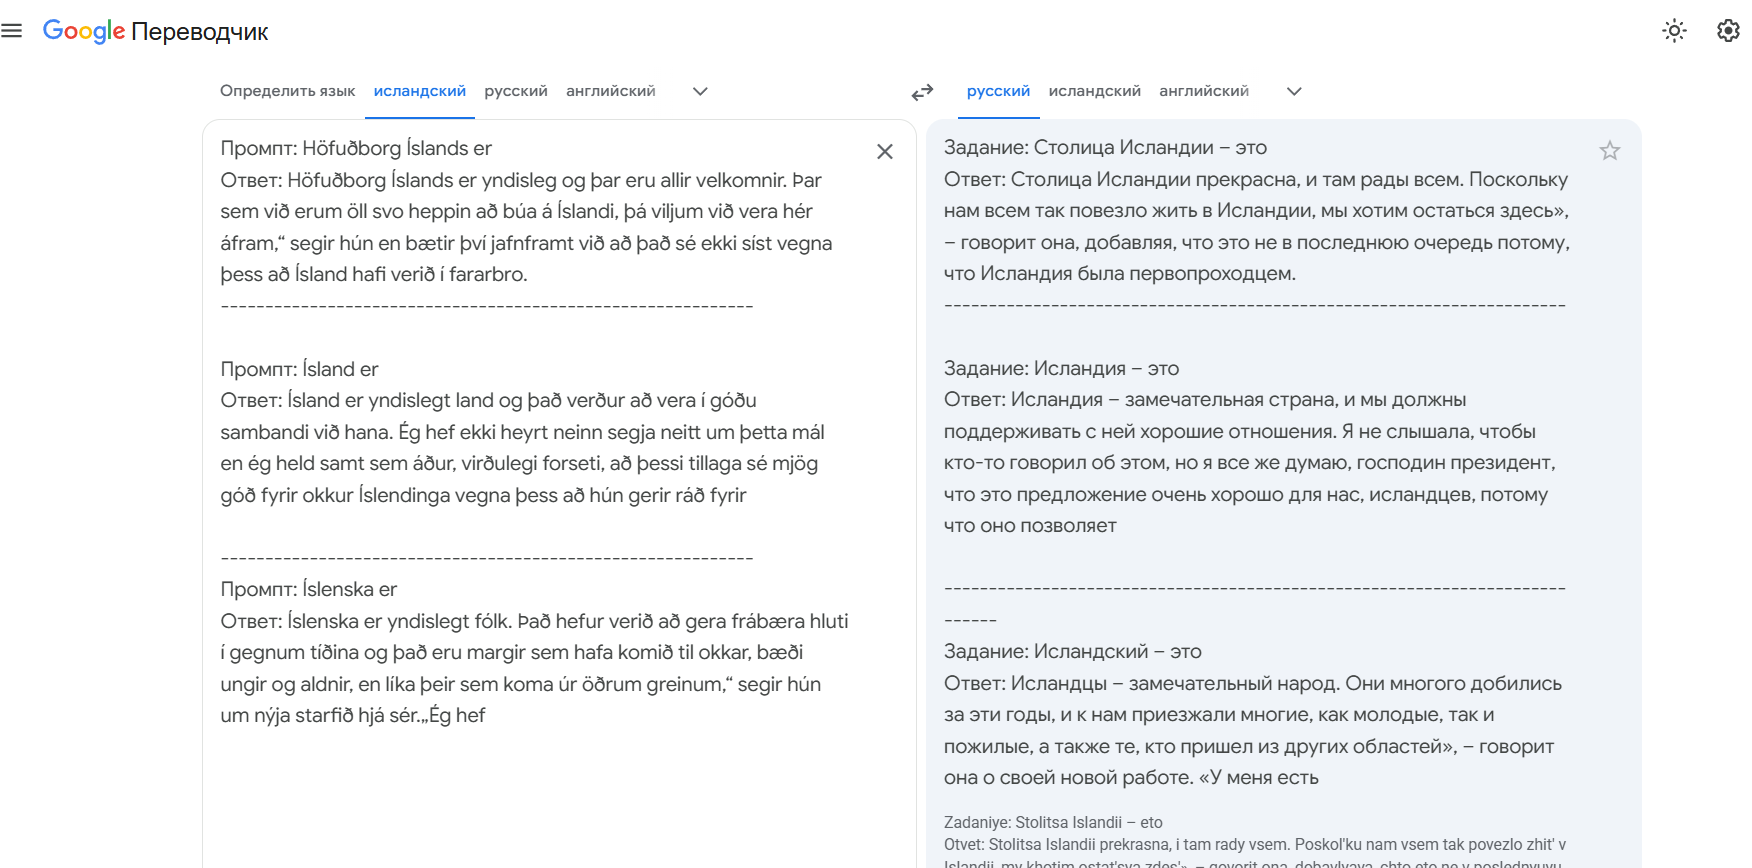

In [3]:
#0.15

from isllm.generation import generate, load_model_from_dir 
import isllm.training
import importlib
importlib.reload(isllm.training)
from isllm.training import generate_simple, load_prompts

for prompt in [
    "Reykjavík er ",
    "Ísland er ", 
    "Íslenska er ", 
    "Jón Sigurðsson var ", 
    "Halldór Laxness hlaut ", 
    "Þingvellir eru ",  
    "Höfuðborg Íslands ", 
    "Hvannadalshnúkur er ", 
    "Eitt sinn, snemma morguns ",
    "Orðabók lýsir "
]:
    out = generate_simple( 
        model=model, 
        tokenizer=tokenizer, 
        prompt=prompt, 
        max_new_tokens=40, 
        temperature=0.15,
        device=device
    )
    print("\n---", prompt)
    print(out)


--- Reykjavík er 
Reykjavík er yndisleg borg. Hún hefur verið í eyði frá því að hún var byggð árið 1930 og þar til nú, en það eru ekki nema örfá ár síðan henni var lokað á ný eftir miklar þrengingar

--- Ísland er 
Ísland er yndislegt land og við erum að vinna í því. Við höfum verið með mjög gott lið, bæði hér heima sem erlendis,“ sagði Arnar Þór Viðarsson þjálfari Víkings eftir leik kvöldsins.„Við vorum

--- Íslenska er 
Íslenska er yndislegt fólk og það eru allir velkomnir. Það verður gaman að sjá hvernig þetta fer allt saman,“ segir hún um nýja starfið sem hefst í haust en þar mun hún meðal annars starfa við leiklist

--- Jón Sigurðsson var 
Jón Sigurðsson var yst á hálum ís þegar hann sá að það voru ekki bara þeir sem höfðu verið í kringum hann. Hann sagði: „Ég er búinn að vera hérna síðan ég man eftir mér.“ Og þá kom

--- Halldór Laxness hlaut 
Halldór Laxness hlaut zenostictica árið 1935, en hann er einn af stofnendum og aðalhöfundar bókarinnar. Hann var einnig höfundur að bókin

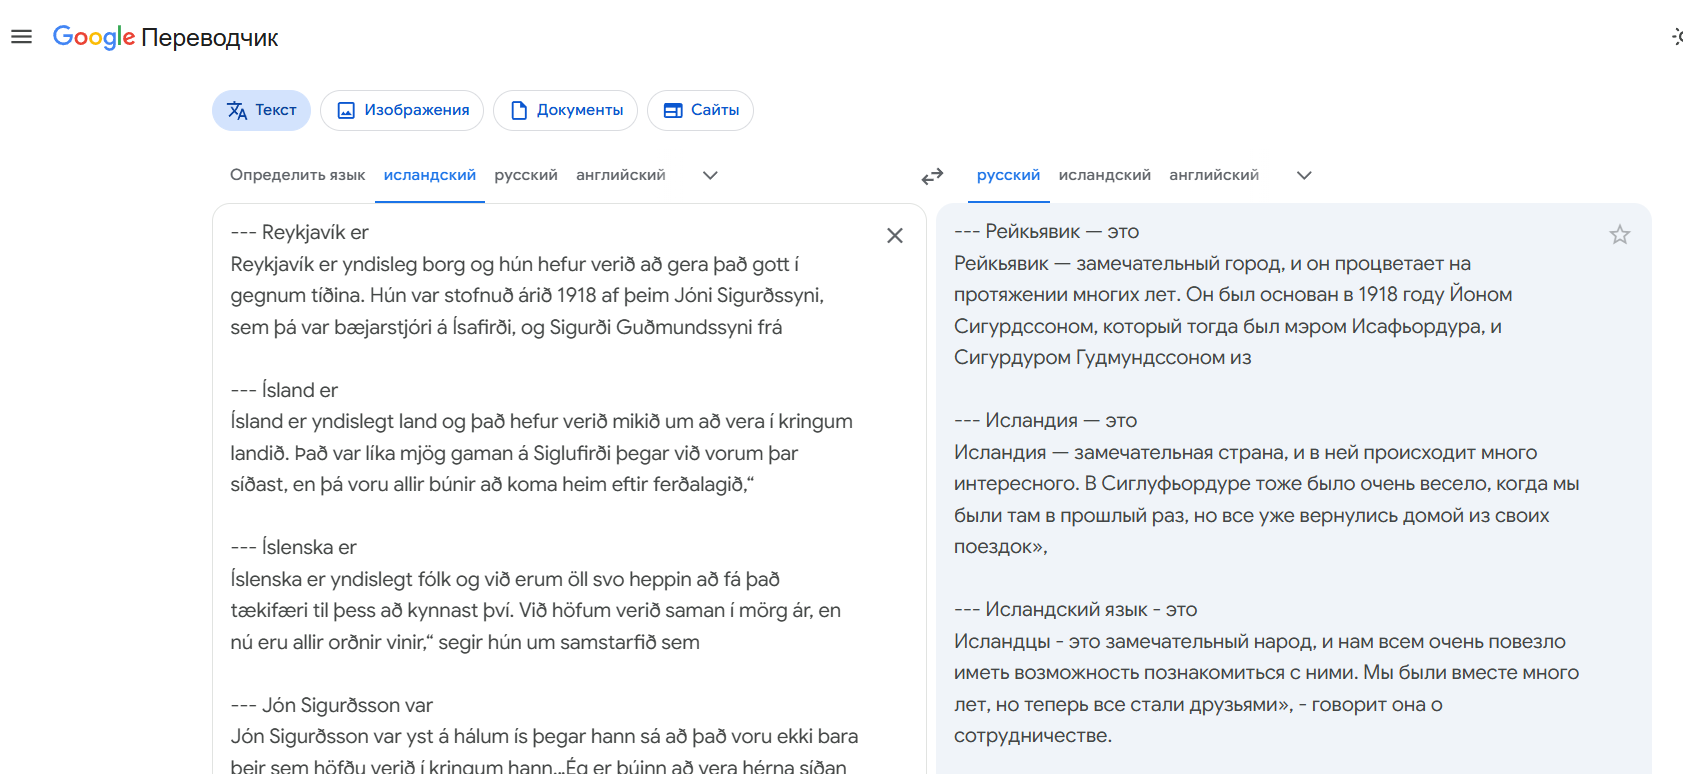

In [4]:
#0.5

for prompt in [
    "Reykjavík er ",
    "Ísland er ", 
    "Íslenska er ", 
    "Jón Sigurðsson var ", 
    "Halldór Laxness hlaut ", 
    "Þingvellir eru ",  
    "Höfuðborg Íslands ", 
    "Hvannadalshnúkur er ", 
    "Eitt sinn, snemma morguns ",
    "Orðabók lýsir "
]:
    out = generate_simple( 
        model=model, 
        tokenizer=tokenizer, 
        prompt=prompt, 
        max_new_tokens=40, 
        temperature=0.5,
        device=device
    )
    print("\n---", prompt)
    print(out)


--- Reykjavík er 
Reykjavík er yndisleg borg. Hún var byggð árið 1939 og hefur verið í um það bil tíu ár, en nú eru íbúar hennar orðnir átta þúsund talsins. Borgin stendur á gömlum merg þar sem hún

--- Ísland er 
Ísland er yndislegur staður, en hún hefur verið í eigu Íslendinga frá því að hann var stofnaður árið 1931. „Við vorum bara með þessa hugmynd og við erum mjög stolt af henni,“ segir Katrín Jakobsdóttir forsætisráðherra

--- Íslenska er 
Íslenska er yndislegt og það má ekki missa sig yfir því að hafa tekið þátt í þessu. Það verður bara svo gaman þegar við förum aftur til baka,“ segir hún um fyrstu kynni sín af Íslandi sem eru nú

--- Jón Sigurðsson var 
Jón Sigurðsson var yst á hálum ís og lét ekki til sín taka. Hann hefur verið í hópi þeirra sem hafa gagnrýnt hann fyrir að vera of þungur, en nú er það orðið ljóst að hann getur ekki setið

--- Halldór Laxness hlaut 
Halldór Laxness hlaut antik-verðlaunin í bókmenntaþættinum Orð*um bækur á Rás 1. Hann segir að það hafi verið er

## Разные seed 

In [5]:
for seed in [1, 2, 3]:
    out = generate(model, tokenizer, "Einu sinni, snemma morguns", max_new_tokens=60,
                   temperature=0.9, top_k=50, do_sample=True, seed=seed, device=device)
    print(f"\n[seed {seed}]", out)


[seed 1] Einu sinni, snemma morguns, fór ég á tónleika í Háskólabíói og sat þar með hljómsveitinni Tjarnarpálmanum. Ég varð hálfvegis hissa enda hafði ég ekki heyrt meira af þessu orði, ekki einu sinni fengið það fyrr en daginn eftir. Ég hafði verið að hlusta á Söngvakeppni sjónvarpsins,

[seed 2] Einu sinni, snemma morguns, voru konur teknar af skarið þegar þeir voru einir heima og þurftu að ganga að öllum kúlunni í kringum þá í tösku sem þeim var búin af þeim í. „Ég held að það hafi verið um 200 konur sem hafi verið teknar af þeim. Þær fengu ekki að heyra þessa hugmynd,"

[seed 3] Einu sinni, snemma morguns, þegar ég stóð upp, sagði hún mér þá, að það ætti að draga úr stuðningi við fátæk börn á Íslandi. Það var ekki til þess að koma þeim aftur til vinnu og til að mennta þau. Þetta væri ekki eins og það ætti að vera, þetta ætti ekki að vera vandamál. Við fengum


### 1. Постановка эксперимента по проверке выучила ли модель факты
Тест для оценки фактологических знаний модели. 
*   **Входные данные:** 10 фактов об Исландии, например, столица, высочайшая гора, первый президент и т.д.. Каждый факт проверяется через 3–4 различных формулировки (парафразы).
*   **Механика:** Модель не генерирует текст. Ей дается префикс, например, `"Höfuðborg Íslands er — "`, и она должна выбрать правильный ответ из списка кандидатов (6  штук). Выбор происходит на основе вычисления логарифма вероятности logprob для каждого варианта.
*   **Метрики:** 
    *   `Accuracy@1` - правильный ответ оказался на 1-м месте.
    *   `Accuracy@5` - правильный ответ попал в топ-5.
    *   `MRR` - средняя обратная величина ранга (чем выше, тем лучше).
    *   `Consistency` - отвечает ли модель правильно во всех парафразах одного и того же факта.

Дело в том, что модели на 50M параметров могут генерировать грамматически связный текст, не обладая реальными фактами (просто заучивая шаблоны), а здесь мы проверяем знание вактов и понимание вопроса. Оценка вероятности конкретных токенов-ответов позволяет изолировать фактологические знания от способности строить предложения. При этом мы проверяем несколько формулировок одного вопроса, тк это проверка на понимание семантики вопроса. Если модель выбирает правильный ответ на фразу «Столица Исландии», но путается на фразе «Какой город является центром правительства Исландии?», значит она не выучила факт, а просто запомнила пару слов.

In [6]:
from isllm.benchmark import perplexity

val_texts = []
with open("data/prepared/val.txt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if len(line) > 20:
            val_texts.append(line)
        if len(val_texts) >= 100:
            break

print("val texts:", len(val_texts))
print("Perplexity:", round(perplexity(model, tokenizer, val_texts, device=device), 2))

val texts: 100
Perplexity: 14.43


In [7]:
import torch
from isllm.benchmark import load_facts, score_continuations
facts = load_facts("isllm/facts_is.json")
device = "cuda" if torch.cuda.is_available() else "cpu"

total_acc1 = 0
total_acc5 = 0
total_mrr = 0.0
total_items = 0
consistent_facts = 0


for fact_idx, fact in enumerate(facts, 1):
    correct = fact["answer"]
    candidates = fact["candidates"]
    formulations = fact["formulations"]
    
    print(f"\n[{fact_idx}/{len(facts)}] Факт: {fact['fact']}")
    print(f"Правильный ответ: '{correct}'")
    
    fact_ranks = []
    
    for f_idx, f in enumerate(formulations, 1):
        prefix = f["prefix"]
        print(f"\n  Вариант {f_idx}: '{prefix}'")

        scores = score_continuations(model, tokenizer, prefix, candidates, device)
        
        correct_rank = next((r for c, _, r in scores if c == correct), 99)
        fact_ranks.append(correct_rank)
        
        total_items += 1
        if correct_rank == 1:
            total_acc1 += 1
        if correct_rank <= 5:
            total_acc5 += 1
        total_mrr += 1.0 / correct_rank
        
        for rank, (cand, logp, original_rank) in enumerate(scores[:3], 1):
            marker = "+" if cand == correct else "-"
            print(f"      {rank}. {marker} '{cand}' | logprob: {logp:.4f}")
        
        if correct_rank > 3:
            correct_logp = next((lp for c, lp, r in scores if c == correct), float('nan'))
            print(f"...")
            print(f"{correct_rank}. + '{correct}' | logprob: {correct_logp:.4f}")
        
        if correct_rank == 1:
            print(f"Верно, правильный ответ имеет ранг 1")
        else:
            print(f"Правильный ответ на ранге {correct_rank}")
    
    is_consistent = all(r == 1 for r in fact_ranks)
    if is_consistent:
        consistent_facts += 1
        print(f"\n  Итог по факту: во всех парафразах верно")
    else:
        print(f"\n  Итог по факту: ранги: {fact_ranks}")

print("\n" + "=" * 80)
print("ИТОГОВАЯ СТАТИСТИКА")
print("=" * 80)
print(f"Всего проверок (парафраз): {total_items}")
print(f"Accuracy@1: {total_acc1 / total_items:.3f} (доля правильных ответов на 1-м месте)")
print(f"Accuracy@5: {total_acc5 / total_items:.3f} (доля правильных ответов в топ-5)")
print(f"MRR (Mean Reciprocal Rank): {total_mrr / total_items:.3f}")
print(f"Consistency (устойчивость к перефразированию): {consistent_facts}/{len(facts)} ({consistent_facts/len(facts):.1%})")


[1/10] Факт: Höfuðborg Íslands
Правильный ответ: 'Reykjavík'

  Вариант 1: 'Höfuðborg Íslands er — '
      1. + 'Reykjavík' | logprob: -0.4514
      2. - 'Akureyri' | logprob: -0.6064
      3. - 'Hafnarfjörður' | logprob: -0.9710
Верно, правильный ответ имеет ранг 1

  Вариант 2: 'Hvaða borg er höfuðborg Íslands? Svarið er — '
      1. + 'Reykjavík' | logprob: -0.3701
      2. - 'Akureyri' | logprob: -0.5209
      3. - 'Hafnarfjörður' | logprob: -0.7338
Верно, правильный ответ имеет ранг 1

  Вариант 3: 'Höfuðstaður Íslands heitir — '
      1. + 'Reykjavík' | logprob: -0.1693
      2. - 'Hafnarfjörður' | logprob: -1.0943
      3. - 'Akureyri' | logprob: -1.4649
Верно, правильный ответ имеет ранг 1

  Вариант 4: 'Borgin sem er aðsetur ríkisstjórnar Íslands er — '
      1. + 'Reykjavík' | logprob: -0.2884
      2. - 'Hafnarfjörður' | logprob: -0.9154
      3. - 'Akureyri' | logprob: -1.4379
Верно, правильный ответ имеет ранг 1

  Итог по факту: во всех парафразах верно

[2/10] Факт: Rit

## Вывод:

**Модель всё еще не всегда продолжает текст уместным образом:**

- не различает, когда требуется энциклопидеческий стиль, так как основной массив данных был на новостных текстах интеренета
- вставляет неуместные, незначительные факты, прямую речь, иногда меняет тему
- иногда ошибается в фактах, возможно, их не было в обучающей выборке

**Но при этом:**

- текст грамматически корректен, относительно связный
- модель относительно устойчива к перефразам, усвоила наиболее важные факты
- увеличенная модель лучше справляется: меньше перплексия на валидации (11.0 вместо 13.2), ответы более адекватные по моей оценке, лучше усвоены факты (Accuracy@1 0.48 вместо 0.32)

**Возможные пути улучшения:**

- больше корпус, больше модель, дольше обучение
- SFT по следованию инструкциям